# 07 – Training: Das Netz lernt, Parkfläche zu erkennen

**Ziel.** Vier Netze lernen lassen, je eines für jedes Bild und jede Auflösung, und für jedes die beste Epoche und die Schwelle festlegen.

| Lauf | Luftbild | Auflösung |
| --- | --- | --- |
| `A_5cm`, `A_10cm` | Frühjahr 2021 | 5 cm, 10 cm |
| `B_5cm`, `B_10cm` | Sommer 2024/25 | 5 cm, 10 cm |

**Warum.** Nur mit vier getrennten Läufen lässt sich die Leitfrage beantworten (5 cm gegen 10 cm), und zwar für beide Bilder einzeln (`01b`, Abschnitt 3).

**Welche Daten?** Nur die Kacheln aus Notebook 05:

| Gruppe | Rolle |
| --- | --- |
| **Lernen** | Übungsaufgaben: daraus lernt das Netz |
| **Validieren** | Probeprüfung: nach jeder Lernrunde gemessen; daran werden die beste Epoche und die Schwelle gewählt |
| Testen | kommt hier **nicht** vor (Notebooks 08 bis 10, einmal) |

**Schalter.** Das volle Lernen dauert rund anderthalb Stunden (Grafikkarte mit 12 GB). Es startet nur, wenn die Umgebungsvariable `LANGLAUF=1` gesetzt ist. Ohne Schalter zeigt das Notebook alle Schritte an einem Beispiel und liest die gespeicherten Lernkurven. Der Nachtrag in Abschnitt 11 hat einen eigenen Schalter (`NACHTRAG=1`).

**Eingaben:** `daten/verarbeitet/kacheln/`, `kacheln_index.csv` (Notebook 05), `netz.py` (Bauplan des Netzes).
**Ausgaben:** `ergebnisse/modelle/{Lauf}.pt`, Lernkurven `ergebnisse/training_{Lauf}.csv`, `ergebnisse/schwellen.json`, Protokoll in MLflow (`ergebnisse/mlflow.db`), Abbildungen `07_…`.

In [1]:
import json                        # Einstellungen lesen, Schwellen speichern
import os                          # Umgebungsvariable LANGLAUF lesen
import random                      # Zufall von Python
import time                        # Dauer einer Epoche messen
import logging                     # Meldungen von MLflow leiser stellen
import warnings                    # einen Hinweis ausblenden (siehe unten)
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen
MODELLE = ERG / "modelle"                            # gelernte Netze
MODELLE.mkdir(exist_ok=True)

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
SEED = EINST["SEED"]

warnings.filterwarnings("ignore", message="IProgress not found")   # Hinweis zum Fortschrittsbalken ausblenden: er ändert nichts und nennt den Pfad dieses Rechners

import numpy as np                 # Zufall für das Drehen und Spiegeln
import pandas as pd                # Tabellen
import matplotlib.pyplot as plt    # Abbildungen
import torch                       # neuronale Netze
import torch.nn.functional as F    # Verlustfunktion
from torch.utils.data import Dataset, DataLoader     # Kacheln portionenweise ans Netz geben
import mlflow                      # Lernläufe protokollieren
from netz import DenseUNet, GERAET, MITTEL, STREUUNG, lade_modell   # Bauplan des Netzes (Datei netz.py, erklärt in Abschnitt 3)

In [2]:
logging.getLogger("mlflow").setLevel(logging.WARNING)              # Info-Meldungen von MLflow ausblenden
LANGLAUF = os.environ.get("LANGLAUF") == "1"                       # volles Lernen nur mit Schalter
print("Gerät:", GERAET, "| volles Lernen:", LANGLAUF)
if GERAET == "cuda":
    # Windows lagert bei vollem Grafikspeicher still in den Arbeitsspeicher aus und wird dann sehr langsam.
    # Die Grenze bei 95 % erzeugt stattdessen eine klare Fehlermeldung.
    torch.cuda.set_per_process_memory_fraction(0.95)

index = pd.read_csv(VERARB / "kacheln_index.csv")                  # Inventar der Kacheln (Notebook 05)
index.groupby(["versuch", "aufloesung_cm", "gruppe"]).size().unstack()

Gerät: cuda | volles Lernen: False


gruppe                 lernen  validieren
versuch aufloesung_cm                    
A       5                1700         335
        10                458          87
B       5                1700         335
        10                456          86

**Einstellungen dieses Schritts** (aus den Quellen; nur Bild und Auflösung werden variiert, `01b`, Abschnitt 11, E9 und E10):

| Einstellung | Wert | Bedeutung |
| --- | --- | --- |
| `EPOCHEN` | 16 bei 5 cm, 40 bei 10 cm | eine Epoche = alle Lernkacheln einmal. Bei 10 cm gibt es viermal weniger Kacheln, darum mehr Epochen. Die Zahl richtet sich nach dem Zeitrahmen; die Lernkurve zeigt, ob das reicht |
| `BATCH`, `AKKUMULATION` | 4 und 3 | 4 Kacheln je Portion; nach 3 Portionen wird gemeinsam korrigiert. Das wirkt wie 12 (Quellen), passt aber in 12 GB |
| `LERNRATE`, `ABFALL` | 0,0001 und 0,937 | Schrittgrösse; sie wird nach jeder Epoche mit 0,937 malgenommen: anfangs grobe, später feine Schritte (Hellekes 2022) |
| `SCHWELLEN` | 0,10 bis 0,90 | Kandidaten für die Schwelle, ab der ein Pixel als Parkfläche gilt (Abschnitt 8) |

In [3]:
EPOCHEN = {5: 16, 10: 40}
BATCH, AKKUMULATION = 4, 3
LERNRATE, ABFALL = 1e-4, 0.937
SCHWELLEN = [round(wert, 2) for wert in np.arange(0.10, 0.91, 0.05)]
LAEUFE = [("A", 10), ("B", 10), ("A", 5), ("B", 5)]                # 10 cm zuerst, weil schneller

## 1. Zufall festlegen

Beim Lernen wirkt Zufall an drei Stellen: die Startwerte des Decoders, die Reihenfolge der Kacheln und das zufällige Drehen und Spiegeln. `setze_seed` stellt alle Zufallsgeneratoren (Python, NumPy, PyTorch) auf denselben Startwert. So läuft ein Lauf beim nächsten Mal gleich ab (auf der Grafikkarte bis auf kleine Rundungsunterschiede).

In [4]:
def setze_seed(seed):
    random.seed(seed)                  # Zufall von Python
    np.random.seed(seed)               # Zufall von NumPy (Drehen und Spiegeln)
    torch.manual_seed(seed)            # Zufall von PyTorch (Startwerte, Reihenfolge)
    torch.cuda.manual_seed_all(seed)   # ... auch auf der Grafikkarte

setze_seed(SEED)

## 2. Daten portionenweise bereitstellen

Ein `Dataset` sagt PyTorch, wie man **eine** Kachel holt. Dabei passiert zweierlei:

- **Normierung:** Farbwerte 0 bis 255 werden auf 0 bis 1 gebracht und dann so verschoben und gestreckt, wie es der vortrainierte Encoder von ImageNet gewohnt ist (Mittel und Streuung je Farbe).
- **Drehen und Spiegeln (nur beim Lernen):** Jede Kachel wird zufällig um 0, 90, 180 oder 270° gedreht und in der Hälfte der Fälle gespiegelt. So lernt das Netz, dass ein Parkfeld auch gedreht ein Parkfeld ist.

Ein `DataLoader` stellt daraus **Batches** zusammen: Portionen von 4 Kacheln, die gemeinsam durch das Netz gehen.

In [5]:
class Kacheln(Dataset):
    def __init__(self, versuch, aufloesung_cm, gruppe, drehen):
        auswahl = (index.versuch == versuch) & (index.aufloesung_cm == aufloesung_cm) & (index.gruppe == gruppe)
        self.tabelle = index[auswahl].reset_index(drop=True)         # nur die Kacheln dieses Laufs und dieser Gruppe
        self.drehen = drehen

    def __len__(self):                                               # wie viele Kacheln gibt es?
        return len(self.tabelle)

    def __getitem__(self, i):                                        # Kachel Nummer i holen
        kachel = np.load(VERARB / self.tabelle.datei[i])
        x = torch.from_numpy(kachel["bild"]).float() / 255.0         # Farbwerte 0..255 -> 0..1
        y = torch.from_numpy(kachel["label"].astype(np.int64))       # Lösung 0 / 1 / 255
        if self.drehen:
            k = np.random.randint(4)                                 # 0, 1, 2 oder 3 Vierteldrehungen
            x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (0, 1))
            if np.random.rand() < 0.5:                               # in der Hälfte der Fälle spiegeln
                x, y = torch.flip(x, (2,)), torch.flip(y, (1,))
        return (x - MITTEL) / STREUUNG, y                            # Normierung wie ImageNet

beispiel_x, beispiel_y = Kacheln("A", 5, "lernen", True)[0]
print("Eine Kachel:", tuple(beispiel_x.shape), "(Farben, Zeilen, Spalten) | Lösung:", tuple(beispiel_y.shape))

Eine Kachel: (3, 512, 512) (Farben, Zeilen, Spalten) | Lösung: (512, 512)


## 3. Das Netz: Dense-U-Net

```
Bild 512×512 ─► verkleinern ─► verkleinern ─► … ─► klein, viel "Verständnis"     (Encoder)
                   │              │                       │
                   │  Abkürzungen (Skip-Connections) geben Details weiter │
                   ▼              ▼                       ▼
Karte 512×512 ◄─ vergrössern ◄─ vergrössern ◄─ … ◄─────────┘                     (Decoder)
```

- **Encoder (links):** erkennt, *was* im Bild ist: erst Kanten, dann Formen, dann "Auto", "Strasse". Es ist **DenseNet-121**, schon an 1,2 Millionen Alltagsfotos (ImageNet) vortrainiert. Wir bringen ihm nur noch Luftbilder bei (*Transfer Learning*).
- **Decoder (rechts):** bringt das Wissen zurück auf jeden einzelnen Pixel.
- **Skip-Connections:** geben feine Details direkt weiter, damit Ränder scharf bleiben.
- **Ausgabe:** für jeden Pixel zwei Rohwerte: einer für "keine Parkfläche", einer für "Parkfläche".

Der Bauplan steht als einzige Ausnahme in einer eigenen Datei, `netz.py` (`DenseUNet`), weil Notebook 08 ihn genau gleich wieder braucht (Quellen: Henry 2021, Hellekes 2022).

In [6]:
modell = DenseUNet().to(GERAET)
with torch.no_grad():                                                # nur ausprobieren, nicht lernen
    ausgabe = modell(beispiel_x.unsqueeze(0).to(GERAET))             # unsqueeze: Batch aus 1 Kachel
print("Eingabe:", tuple(beispiel_x.unsqueeze(0).shape), "→ Ausgabe:", tuple(ausgabe.shape), "= (Batch, 2 Klassen, Zeilen, Spalten)")
print("Anzahl lernbarer Zahlen (Gewichte):", f"{sum(p.numel() for p in modell.parameters()):,}".replace(",", "'"))

Eingabe: (1, 3, 512, 512) → Ausgabe: (1, 2, 512, 512) = (Batch, 2 Klassen, Zeilen, Spalten)
Anzahl lernbarer Zahlen (Gewichte): 13'077'410


## 4. Die Fehlernote: Verlustfunktion

Nach jedem Batch bekommt das Netz eine **Fehlernote** (Verlust) und versucht, sie zu verkleinern.

Die **Kreuzentropie** bestraft vor allem *sichere falsche* Antworten: Sagt das Netz "99 % keine Parkfläche", obwohl dort eine ist, ist die Strafe hoch. Pixel mit Lösung 255 zählen nicht (`ignore_index=255`). Das ist der Standard der Quellen. Die seltene Parkfläche wird **nicht** stärker gewichtet: Ein Gewicht wäre ein Wert, den wir nicht prüfen könnten (`01b`, Abschnitt 11, E9). Stattdessen wird in Abschnitt 8 die Schwelle auf der Validierung gewählt.

In [7]:
def verlust(rohwerte, loesung):
    return F.cross_entropy(rohwerte, loesung, ignore_index=255)      # Pixel mit 255 werden übersprungen

note = verlust(ausgabe.float(), beispiel_y.unsqueeze(0).to(GERAET)).item()
print("Fehlernote des ungelernten Netzes für die Beispielkachel:", round(note, 3))

Fehlernote des ungelernten Netzes für die Beispielkachel: 0.605


## 5. Ein einzelner Lernschritt, vorgeführt

So sieht **ein** Schritt aus; das Lernen wiederholt ihn tausendfach:
1. Batch durchs Netz → Vorhersage;
2. Fehlernote berechnen;
3. **Rückwärtsrechnung** (`backward`): für jede der Millionen Zahlen im Netz berechnen, in welche Richtung sie sich ändern muss, damit die Note besser wird;
4. der **Optimierer Adam** macht einen kleinen Schritt in diese Richtung. Die Schrittgrösse heisst **Lernrate**.

Die Note sinkt in dieser Vorführung, weil das Netz sich fünfmal demselben Batch anpasst. Das ist zugleich der **Probelauf vor dem langen Lernen**: Er zeigt, dass Daten, Netz und Verlust zusammenpassen.

In [8]:
optimierer = torch.optim.Adam(modell.parameters(), lr=LERNRATE)
lader = DataLoader(Kacheln("A", 5, "lernen", True), batch_size=BATCH, shuffle=True)   # 4 Kacheln je Batch, gemischt
x, y = next(iter(lader))                                             # ein Batch
x, y = x.to(GERAET), y.to(GERAET)
modell.train()                                                       # Lernmodus
for schritt in range(1, 6):
    note = verlust(modell(x), y)               # 1. und 2.
    optimierer.zero_grad()                     # alte Richtungen vergessen
    note.backward()                            # 3. Rückwärtsrechnung
    optimierer.step()                          # 4. kleiner Schritt
    print(f"Schritt {schritt}: Fehlernote {note.item():.3f}")
del modell, optimierer, lader, x, y, ausgabe                         # Grafikspeicher freigeben
torch.cuda.empty_cache()

Schritt 1: Fehlernote 0.618


Schritt 2: Fehlernote 0.253


Schritt 3: Fehlernote 0.099


Schritt 4: Fehlernote 0.033


Schritt 5: Fehlernote 0.011


## 6. Wie gut ist ein Stand? Bewertung auf der Validierung

Für jeden bewertbaren Pixel vergleichen wir Vorhersage und Lösung:

| | Lösung: Parkfläche | Lösung: keine |
| --- | --- | --- |
| **gemeldet: Parkfläche** | richtig erkannt (TP) | Fehlmeldung (FP) |
| **gemeldet: keine** | übersehen (FN) | richtig (TN) |

- **Genauigkeit** (Precision) = TP ÷ (TP + FP): "Wenn das Netz *Parkfläche* sagt, stimmt es zu … %."
- **Trefferquote** (Recall) = TP ÷ (TP + FN): "Von aller echten Parkfläche findet es … %."
- **IoU** = TP ÷ (TP + FP + FN): Überdeckung von Meldung und Lösung.

"Anteil richtiger Pixel" verwenden wir nicht: Fast alle Pixel sind keine Parkfläche; "immer keine" hätte über 98 % richtig und wäre nutzlos.

Das Netz liefert je Pixel eine **Sicherheit** zwischen 0 und 1 für "Parkfläche" (`softmax`). Gemeldet wird ein Pixel, wenn die Sicherheit über einer **Schwelle** liegt. Die Funktion zählt TP, FP und FN für mehrere Schwellen in einem Durchgang.

In [9]:
@torch.no_grad()                                                     # nur anwenden, nicht lernen
def konfusion(modell, versuch, aufloesung_cm, schwellen=(0.5,)):
    # Zählt auf der Validierung je Schwelle: [richtig erkannt (TP), Fehlmeldung (FP), übersehen (FN)]
    modell.eval()
    zaehler = {schwelle: [0, 0, 0] for schwelle in schwellen}
    for x, y in DataLoader(Kacheln(versuch, aufloesung_cm, "validieren", False), batch_size=8):
        x, y = x.to(GERAET), y.to(GERAET)
        with torch.autocast(GERAET, dtype=torch.float16, enabled=GERAET == "cuda"):
            sicherheit = modell(x).float().softmax(1)[:, 1]          # Sicherheit für "Parkfläche" je Pixel
        for schwelle in schwellen:
            gemeldet = sicherheit > schwelle
            zaehler[schwelle][0] += (gemeldet & (y == 1)).sum().item()
            zaehler[schwelle][1] += (gemeldet & (y == 0)).sum().item()
            zaehler[schwelle][2] += (~gemeldet & (y == 1)).sum().item()
    return zaehler

In [10]:
def kennzahlen(tp, fp, fn):
    return dict(iou=tp / max(tp + fp + fn, 1), precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1))

## 7. Das Lernen

**Schritt 1: eine Epoche.** Die Funktion geht alle Lernkacheln einmal durch. Es ist derselbe Schritt wie in Abschnitt 5, mit zwei Zusätzen:
- **16-Bit-Rechnung** (`autocast`, `GradScaler`): halb so viel Speicher, schneller; das Ergebnis bleibt praktisch gleich.
- **Sammeln:** Erst nach 3 Batches wird korrigiert. Das wirkt wie ein Batch von 12 Kacheln.

In [11]:
def eine_epoche(modell, lader, optimierer, skalierer):
    # Geht alle Lernkacheln einmal durch und gibt die mittlere Fehlernote zurück.
    modell.train()
    summe = 0.0
    for schritt, (x, y) in enumerate(lader, start=1):
        x, y = x.to(GERAET), y.to(GERAET)
        with torch.autocast(GERAET, dtype=torch.float16, enabled=GERAET == "cuda"):
            note = verlust(modell(x), y) / AKKUMULATION              # durch 3 teilen, weil 3 Batches gesammelt werden
        skalierer.scale(note).backward()                             # Rückwärtsrechnung
        summe += note.item() * AKKUMULATION
        if schritt % AKKUMULATION == 0:                              # erst nach 3 Batches korrigieren
            skalierer.step(optimierer)
            skalierer.update()
            optimierer.zero_grad()
    return summe / len(lader)

**Schritt 2: ein ganzer Lauf.** Nach jeder Epoche wird die Lernrate verkleinert, auf der Validierung gemessen (Schwelle 0,5) und die Zeile in die Lernkurve geschrieben. Ist die IoU besser als alle bisherigen, wird dieser Stand gespeichert. Jeder Lauf wird in **MLflow** protokolliert (Einstellungen und Kennzahlen je Epoche).

In [12]:
mlflow.set_tracking_uri("sqlite:///" + (ERG / "mlflow.db").as_posix())   # Protokoll in einer Datei
mlflow.set_experiment("parkflaeche_eigene_ground_truth")
print("Protokoll der Läufe: ergebnisse/mlflow.db (bleibt lokal, nicht im Repository)")   # letzte Zeile ist eine Ausgabe, damit kein Pfad des Rechners angezeigt wird

Protokoll der Läufe: ergebnisse/mlflow.db (bleibt lokal, nicht im Repository)


**Eine Epoche mit Messung.** Die Funktion fasst zusammen, was nach jeder Epoche geschieht: lernen, die Lernrate verkleinern, auf der Validierung messen. Sie gibt eine Zeile der Lernkurve zurück (IoU, Genauigkeit, Trefferquote, Fehlernote, Dauer).

In [13]:
def epoche_mit_messung(modell, lader, optimierer, skalierer, abfall, versuch, aufloesung_cm, epoche):
    # Lernt eine Epoche, verkleinert die Lernrate und misst auf der Validierung; gibt die Zeile für die Lernkurve zurück
    start = time.time()
    note = eine_epoche(modell, lader, optimierer, skalierer)
    abfall.step()                                            # Lernrate für die nächste Epoche verkleinern
    zeile = kennzahlen(*konfusion(modell, versuch, aufloesung_cm)[0.5])
    zeile.update(epoche=epoche, verlust=note, sekunden=round(time.time() - start))
    return zeile

**Der ganze Lauf.** `trainiere` ruft diese Funktion für jede Epoche auf, schreibt die Lernkurve nach jeder Epoche in eine Datei und speichert den Stand des Netzes, sobald er besser ist als alle früheren.

In [14]:
def trainiere(versuch, aufloesung_cm, epochen, name):
    # Lernt einen Lauf über `epochen` Epochen und speichert Lernkurve und besten Stand unter `name`
    setze_seed(SEED)
    lader = DataLoader(Kacheln(versuch, aufloesung_cm, "lernen", True), batch_size=BATCH, shuffle=True, drop_last=True)
    modell = DenseUNet().to(GERAET)
    optimierer = torch.optim.Adam(modell.parameters(), lr=LERNRATE)
    abfall = torch.optim.lr_scheduler.ExponentialLR(optimierer, gamma=ABFALL)
    skalierer = torch.amp.GradScaler()                               # nötig für die 16-Bit-Rechnung
    bestes, verlauf = -1.0, []
    with mlflow.start_run(run_name=name):
        mlflow.log_params(dict(versuch=versuch, aufloesung_cm=aufloesung_cm, epochen=epochen, batch=BATCH,
                               akkumulation=AKKUMULATION, lernrate=LERNRATE, abfall=ABFALL, verlust="cross_entropy", seed=SEED))
        for epoche in range(1, epochen + 1):
            zeile = epoche_mit_messung(modell, lader, optimierer, skalierer, abfall, versuch, aufloesung_cm, epoche)
            verlauf.append(zeile)
            pd.DataFrame(verlauf).to_csv(ERG / f"training_{name}.csv", index=False)
            mlflow.log_metrics({k: zeile[k] for k in ("iou", "precision", "recall", "verlust")}, step=epoche)
            if zeile["iou"] > bestes:                                # neuer bester Stand -> speichern
                bestes = zeile["iou"]
                torch.save(modell.state_dict(), MODELLE / f"{name}.pt")
            print(f"{name} Epoche {epoche}: IoU {zeile['iou']:.3f} (bestes {bestes:.3f}), {zeile['sekunden']} s")
        mlflow.log_metric("beste_val_iou", bestes)

**Schritt 3: alle vier Läufe.** Nur mit dem Schalter `LANGLAUF=1`. Das Protokoll des Lernlaufs vom 27.11.2026 (eine Zeile je Epoche) liegt in `ergebnisse/training_protokoll.txt`; dieselben Zahlen stehen in den Lernkurven `ergebnisse/training_{Lauf}.csv`.

In [15]:
if LANGLAUF:
    for versuch, aufloesung_cm in LAEUFE:
        trainiere(versuch, aufloesung_cm, EPOCHEN[aufloesung_cm], f"{versuch}_{aufloesung_cm}cm")
else:
    print("Kein volles Lernen (LANGLAUF nicht gesetzt). Es werden die gespeicherten Lernkurven und Netze verwendet.")

Kein volles Lernen (LANGLAUF nicht gesetzt). Es werden die gespeicherten Lernkurven und Netze verwendet.


## 8. Lernkurven

Links die Fehlernote auf den Lernkacheln, rechts die IoU auf der Validierung, je Epoche. Der Punkt markiert den gespeicherten besten Stand. Blau: 5 cm, orange: 10 cm. Durchgezogen: Versuch A (2021), gestrichelt: Versuch B (2024/25).

**Worauf man achten muss.** Hat ein Lauf **ausgelernt**? Die beste Epoche allein sagt das nicht: Auf einer flachen, leicht zitternden Kurve kann der höchste Wert zufällig am Ende liegen. Darum vergleichen wir zwei Mittelwerte: die IoU im **letzten Viertel** der Epochen und im **Viertel davor**. Steigt die IoU dazwischen um mehr als 0,01, lernt das Netz noch (`steigt_noch`); sonst ist die Kurve flach. Die Grenze von 0,01 ist gesetzt (ein Hundertstel), nicht gemessen.

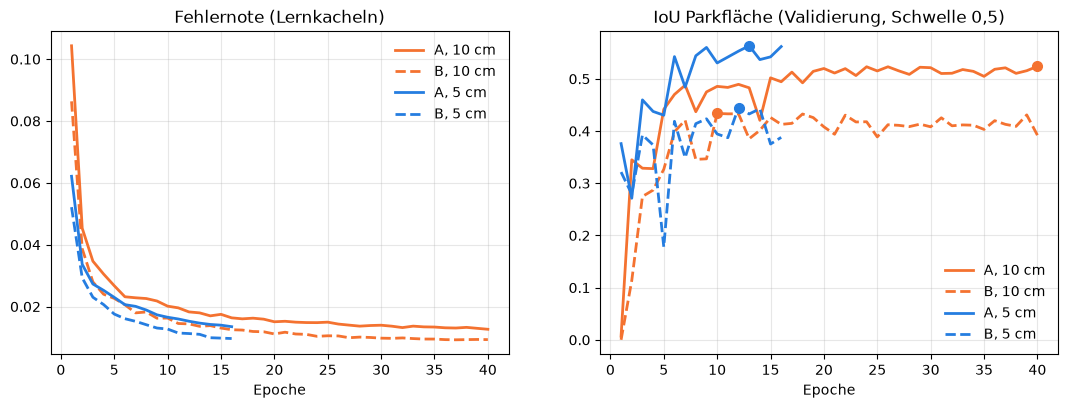

,epochen,beste_epoche,iou_beste,iou_viertel_davor,iou_letztes_viertel,steigt_noch,minuten
lauf,,,,,,,
A_10cm,40,40,0.524,0.517,0.515,False,17
B_10cm,40,10,0.434,0.410,0.413,False,17
A_5cm,16,13,0.563,0.546,0.551,False,25
B_5cm,16,12,0.445,0.413,0.410,False,25


In [16]:
FARBE = {5: "#257de0", 10: "#f47230"}                                # Projektfarben der Auflösungen
STRICH = {"A": "-", "B": "--"}                                       # Versuch A durchgezogen, B gestrichelt
fig, achsen = plt.subplots(1, 2, figsize=(13, 4.2))
uebersicht = []
for versuch, aufloesung_cm in LAEUFE:
    kurve = pd.read_csv(ERG / f"training_{versuch}_{aufloesung_cm}cm.csv")
    stil = dict(color=FARBE[aufloesung_cm], linestyle=STRICH[versuch], linewidth=2, label=f"{versuch}, {aufloesung_cm} cm")
    achsen[0].plot(kurve.epoche, kurve.verlust, **stil)
    achsen[1].plot(kurve.epoche, kurve.iou, **stil)
    beste = kurve.loc[kurve.iou.idxmax()]                            # Zeile der besten Epoche
    achsen[1].plot(beste.epoche, beste.iou, "o", color=FARBE[aufloesung_cm], markersize=7)
    viertel = len(kurve) // 4                                        # Länge eines Viertels in Epochen
    letztes, davor = kurve.iou.iloc[-viertel:].mean(), kurve.iou.iloc[-2 * viertel:-viertel].mean()
    uebersicht.append(dict(lauf=f"{versuch}_{aufloesung_cm}cm", epochen=len(kurve), beste_epoche=int(beste.epoche), iou_beste=round(beste.iou, 3),
                           iou_viertel_davor=round(davor, 3), iou_letztes_viertel=round(letztes, 3), steigt_noch=bool(letztes - davor > 0.01),
                           minuten=round(kurve.sekunden.sum() / 60)))
achsen[0].set_title("Fehlernote (Lernkacheln)")
achsen[1].set_title("IoU Parkfläche (Validierung, Schwelle 0,5)")
for ax in achsen:
    ax.set_xlabel("Epoche"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig(ABB / "07_lernkurven.png", dpi=130, bbox_inches="tight")
plt.show()
pd.DataFrame(uebersicht).set_index("lauf")

**Was die Abbildung zeigt** (Lernlauf vom 27.11.2026). Links: Die Fehlernote auf den Lernkacheln sinkt bei allen vier Läufen bis zum Schluss. Rechts: Die IoU auf der Validierung steigt in den ersten Epochen und bleibt dann etwa auf einer Höhe. Sie zittert von Epoche zu Epoche, bei 5 cm stärker als bei 10 cm.

**Auffällig bei Versuch B (gestrichelt).** Der beste Stand liegt früh (siehe `beste_epoche`). Danach sinkt die Fehlernote weiter, die IoU auf der Validierung aber nicht mehr. Das Netz passt sich dann genauer an die Lernkacheln an, ohne auf neuen Kacheln besser zu werden. Das nennt man **Überanpassung**. Für das Ergebnis ist das kein Schaden, weil je Lauf der beste Stand gespeichert ist und nicht der letzte.

**Auffällig bei `A_10cm`.** Die beste Epoche ist die letzte (40 von 40). Nach `01b`, 7.4 ist dann nicht belegt, dass die Kurve ihr Maximum erreicht hat; der Lauf wäre zu verlängern. Im ersten Lauf wurde das nicht gemacht (`01b`, Abschnitt 11.1). Der Vergleich der Viertel zeigt, dass die Kurve seit Epoche 20 kaum noch steigt. Der Punkt steht als Grenze in Notebook 10. Nachgeholt wird die Verlängerung als Gegenprobe in Abschnitt 11.

**Die Tabelle.** In der Tabelle steht je Lauf die beste Epoche und der Vergleich der beiden letzten Viertel. `steigt_noch = True` heisst: Die IoU ist im letzten Viertel noch um mehr als 0,01 gestiegen; ein längerer Lauf hätte vermutlich mehr gebracht. Das wäre dann eine Grenze dieses Ergebnisses und keine Aussage über die Auflösung.

## 9. Die Schwelle wählen

**Worum es geht.** Bisher galt ein Pixel als Parkfläche, wenn die Sicherheit über 0,5 liegt. Weil Parkfläche selten ist, neigt das Netz zu tiefen Sicherheiten; die beste Schwelle kann tiefer liegen. Wir probieren auf der **Validierung** alle Kandidaten aus und nehmen je Lauf die Schwelle mit der höchsten IoU. Danach ist sie eingefroren: Die Testblöcke werden mit genau dieser Schwelle ausgewertet (`01b`, Abschnitt 11, E9).

**Schritt 1: für jeden Lauf das beste Netz laden und alle Schwellen messen.**

In [17]:
schwellen, kurven = {}, {}
for versuch, aufloesung_cm in LAEUFE:
    name = f"{versuch}_{aufloesung_cm}cm"
    modell = lade_modell(name)                                       # gespeicherter bester Stand dieses Laufs
    zaehler = konfusion(modell, versuch, aufloesung_cm, SCHWELLEN)
    kurven[name] = pd.Series({schwelle: kennzahlen(*werte)["iou"] for schwelle, werte in zaehler.items()})   # IoU je Schwelle
    beste = float(kurven[name].idxmax())                             # Schwelle mit der höchsten IoU
    schwellen[name] = dict(schwelle=beste, iou_validierung=round(float(kurven[name].max()), 4),
                           iou_bei_0_5=round(float(kurven[name][0.5]), 4), **{k: round(v, 4) for k, v in kennzahlen(*zaehler[beste]).items() if k != "iou"})
    del modell
    torch.cuda.empty_cache()
(ERG / "schwellen.json").write_text(json.dumps(schwellen, indent=2), encoding="utf-8")
pd.DataFrame(schwellen).T

,schwelle,iou_validierung,iou_bei_0_5,precision,recall
A_10cm,0.40,0.5296,0.5239,0.6873,0.6978
B_10cm,0.50,0.4337,0.4337,0.6300,0.5820
A_5cm,0.45,0.5659,0.5633,0.7077,0.7385
B_5cm,0.35,0.4657,0.4451,0.6249,0.6464


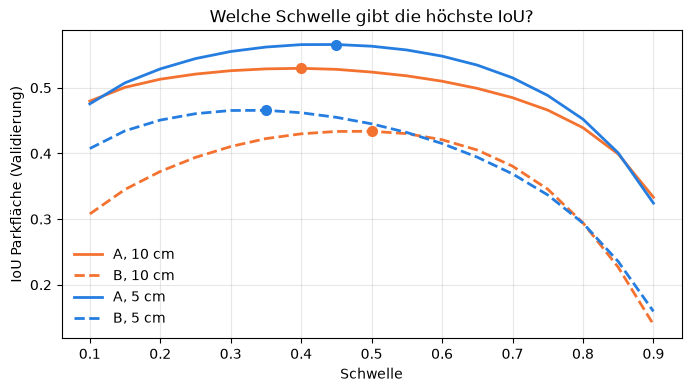

In [18]:
# Abbildung: IoU auf der Validierung je Schwelle, für alle vier Läufe
fig, ax = plt.subplots(figsize=(8, 4))
for versuch, aufloesung_cm in LAEUFE:
    name = f"{versuch}_{aufloesung_cm}cm"
    ax.plot(kurven[name].index, kurven[name].values, color=FARBE[aufloesung_cm], linestyle=STRICH[versuch], linewidth=2, label=f"{versuch}, {aufloesung_cm} cm")
    ax.plot(schwellen[name]["schwelle"], schwellen[name]["iou_validierung"], "o", color=FARBE[aufloesung_cm], markersize=7)
ax.set_xlabel("Schwelle"); ax.set_ylabel("IoU Parkfläche (Validierung)")
ax.set_title("Welche Schwelle gibt die höchste IoU?")
ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig(ABB / "07_schwelle.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jede Linie ist ein Lauf; der Punkt ist die gewählte Schwelle. Ist die Linie um den Punkt herum flach, hängt das Ergebnis kaum von der genauen Schwelle ab.

## 10. Fehler sehen: eine Validierungskachel

Eine Validierungskachel mit Parkfläche, für die Läufe `A_5cm` und `A_10cm`. Grün: richtig erkannt. Rot: Fehlmeldung. Blau: übersehen.

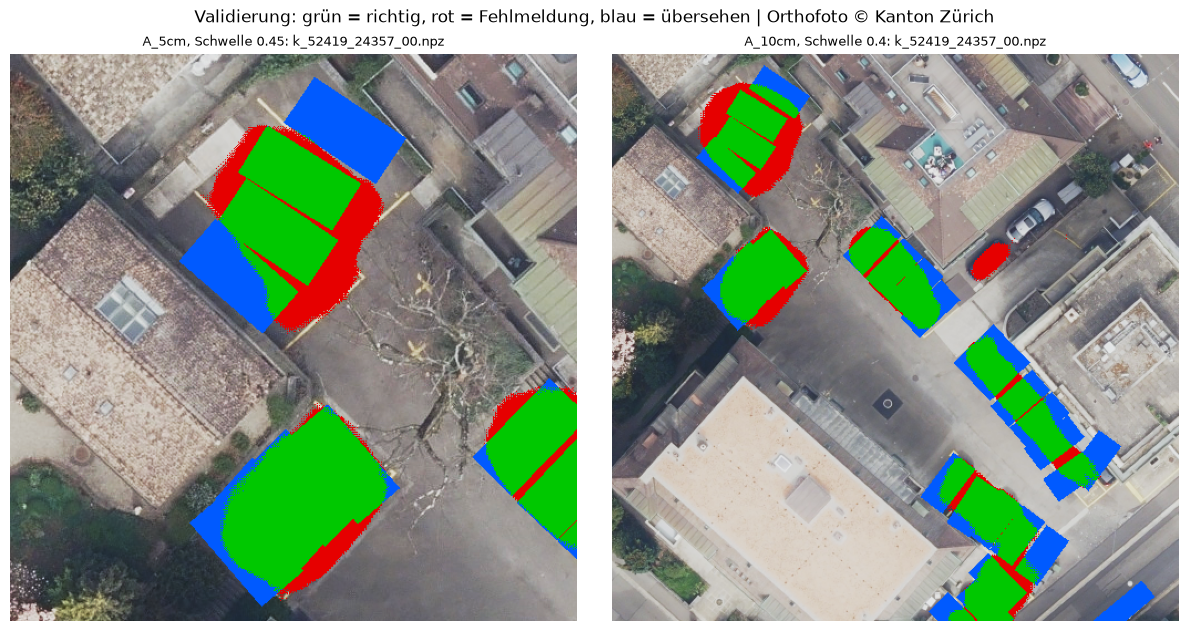

In [19]:
auswahl = index[(index.versuch == "A") & (index.gruppe == "validieren") & (index.anteil_park > 0.08)]
kachel_name = auswahl[auswahl.aufloesung_cm == 10].sample(1, random_state=SEED).kachel.iloc[0]      # ein Ausschnitt, der in beiden Auflösungen vorkommt
fig, achsen = plt.subplots(1, 2, figsize=(12, 6.2), layout="constrained")
for ax, aufloesung_cm in zip(achsen, [5, 10]):
    name = f"A_{aufloesung_cm}cm"
    zeile = auswahl[(auswahl.aufloesung_cm == aufloesung_cm) & (auswahl.kachel == kachel_name)].iloc[0]
    kachel = np.load(VERARB / zeile.datei)
    x = (torch.from_numpy(kachel["bild"]).float() / 255.0 - MITTEL) / STREUUNG
    with torch.no_grad():
        sicherheit = lade_modell(name)(x.unsqueeze(0).to(GERAET)).softmax(1)[0, 1].cpu().numpy()
    gemeldet, loesung = sicherheit > schwellen[name]["schwelle"], kachel["label"]
    farbbild = kachel["bild"].transpose(1, 2, 0).copy()
    farbbild[gemeldet & (loesung == 1)] = (0, 200, 0)                # richtig erkannt: grün
    farbbild[gemeldet & (loesung == 0)] = (230, 0, 0)                # Fehlmeldung: rot
    farbbild[~gemeldet & (loesung == 1)] = (0, 90, 255)              # übersehen: blau
    ax.imshow(farbbild); ax.set_axis_off()
    ax.set_title(f"{name}, Schwelle {schwellen[name]['schwelle']}: {Path(zeile.datei).name}", fontsize=9)
fig.suptitle("Validierung: grün = richtig, rot = Fehlmeldung, blau = übersehen | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "07_validierung_beispiel.png", dpi=100, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Dieselbe Stelle, links ein Viertel des Ausschnitts bei 5 cm, rechts der ganze Ausschnitt bei 10 cm. Grüne Flächen hat das Netz richtig gefunden. Rote und blaue Ränder zeigen, wo Meldung und Lösung nicht genau übereinanderliegen.

## 11. Nachtrag: den Lauf `A_10cm` länger lernen

**Worum es geht.** Beim Lauf `A_10cm` war die beste Epoche die letzte (Abschnitt 8). Dann ist nicht belegt, dass das Netz ausgelernt hat. Der Auftraggeber hat am 27.11.2026 freigegeben, das nachzuholen. Die Regeln dafür stehen in `01b`, Abschnitt 11.2 (N2), und wurden vor dem Rechnen festgelegt:

| Regel | Wert |
| --- | --- |
| Was wird gelernt? | derselbe Lauf noch einmal von vorn, mit 60 statt 40 Epochen; alles andere gleich |
| Name | `A_10cm_lang` |
| Welcher Stand? | die Epoche mit der höchsten IoU auf der Validierung, wie bisher |
| Schwelle | für diesen Stand auf der Validierung neu gewählt, wie in Abschnitt 9 |
| Was gilt? | Der erste Lauf bleibt das Ergebnis. Der längere Lauf ist eine **Gegenprobe** (Notebook 11) |

**Warum von vorn?** Vom ersten Lauf ist nur der beste Stand gespeichert, nicht der Zustand des Optimierers. Ein Weiterlernen ab Epoche 40 wäre darum nicht derselbe Lauf.

**Schritt 1: lernen.** Nur mit dem Schalter `NACHTRAG=1` (rund 25 Minuten). Ohne Schalter werden die gespeicherte Lernkurve und das gespeicherte Netz verwendet.

In [20]:
EPOCHEN_NACHTRAG = 60                                                # 40 und die Hälfte dazu (01b, Abschnitt 11.2, N2)
NACHTRAG = os.environ.get("NACHTRAG") == "1"                         # der Nachtrag lernt nur mit diesem Schalter
if NACHTRAG:
    trainiere("A", 10, EPOCHEN_NACHTRAG, "A_10cm_lang")
else:
    print("Kein Lernen (NACHTRAG nicht gesetzt). Es werden die gespeicherte Lernkurve und das gespeicherte Netz verwendet.")

Kein Lernen (NACHTRAG nicht gesetzt). Es werden die gespeicherte Lernkurve und das gespeicherte Netz verwendet.


**Schritt 2: beide Lernkurven nebeneinander.** Orange: der erste Lauf mit 40 Epochen. Dunkelgrau: der längere Lauf mit 60 Epochen. Die gestrichelte Linie steht bei Epoche 40.

Zwei Fragen an die Kurven:
- **Wie gleich sind zwei Lernläufe?** Bis Epoche 40 haben beide Läufe dieselben Einstellungen. Auf der Grafikkarte laufen sie trotzdem nicht bis auf die letzte Stelle gleich ab. Der Abstand der Kurven in den Epochen 1 bis 40 zeigt, wie viel das ausmacht.
- **Bringt längeres Lernen etwas?** Dazu vergleichen wir im längeren Lauf die beste IoU der Epochen 1 bis 40 mit der besten IoU der Epochen 41 bis 60.

In [21]:
erst = pd.read_csv(ERG / "training_A_10cm.csv")                      # erster Lauf, 40 Epochen
lang = pd.read_csv(ERG / "training_A_10cm_lang.csv")                 # längerer Lauf, 60 Epochen
gemeinsam = lang[lang.epoche <= len(erst)]                           # die Epochen 1 bis 40 des längeren Laufs
danach = lang[lang.epoche > len(erst)]                               # die Epochen 41 bis 60
abstand = (gemeinsam.iou.values - erst.iou.values)                   # längerer Lauf minus erster Lauf, je Epoche
print(f"Epochen 1 bis 40, IoU längerer Lauf minus erster Lauf: im Mittel {abstand.mean():+.3f}, grösster Betrag {np.abs(abstand).max():.3f}")
print(f"Längerer Lauf: beste IoU in den Epochen 1 bis 40: {gemeinsam.iou.max():.3f} | in den Epochen 41 bis 60: {danach.iou.max():.3f}")
viertel = len(lang) // 4                                             # ein Viertel = 15 Epochen
letztes, davor = lang.iou.iloc[-viertel:].mean(), lang.iou.iloc[-2 * viertel:-viertel].mean()
zeilen = []
for name, kurve in [("A_10cm", erst), ("A_10cm_lang", lang)]:
    beste = kurve.loc[kurve.iou.idxmax()]
    zeilen.append(dict(lauf=name, epochen=len(kurve), beste_epoche=int(beste.epoche), iou_beste=round(beste.iou, 3), minuten=round(kurve.sekunden.sum() / 60)))
print(f"Längerer Lauf: IoU im letzten Viertel {letztes:.3f}, im Viertel davor {davor:.3f} → steigt noch: {bool(letztes - davor > 0.01)}")
pd.DataFrame(zeilen).set_index("lauf")

Epochen 1 bis 40, IoU längerer Lauf minus erster Lauf: im Mittel +0.000, grösster Betrag 0.018
Längerer Lauf: beste IoU in den Epochen 1 bis 40: 0.527 | in den Epochen 41 bis 60: 0.527
Längerer Lauf: IoU im letzten Viertel 0.520, im Viertel davor 0.516 → steigt noch: False


,epochen,beste_epoche,iou_beste,minuten
lauf,,,,
A_10cm,40,40,0.524,17
A_10cm_lang,60,55,0.527,25


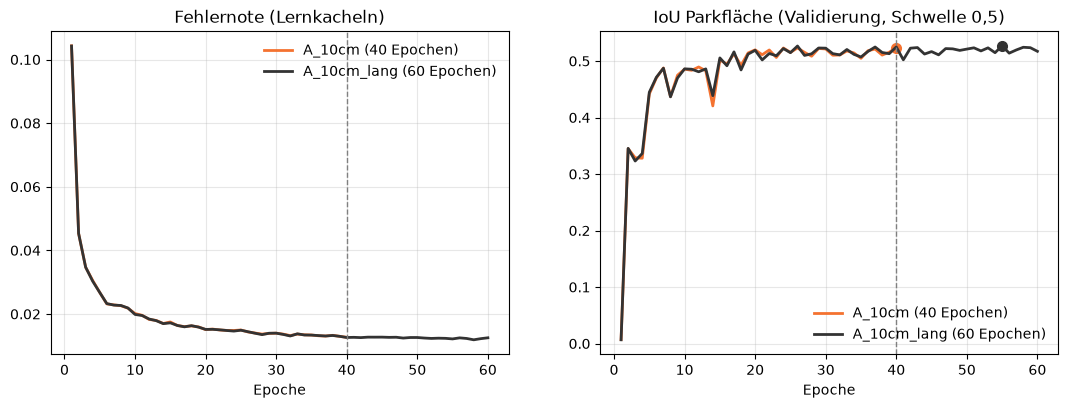

In [22]:
# Abbildung: Fehlernote und IoU je Epoche für beide Läufe; die gestrichelte Linie steht bei Epoche 40
fig, achsen = plt.subplots(1, 2, figsize=(13, 4.2))
for kurve, farbe, name in [(erst, FARBE[10], "A_10cm (40 Epochen)"), (lang, "#333333", "A_10cm_lang (60 Epochen)")]:
    achsen[0].plot(kurve.epoche, kurve.verlust, color=farbe, linewidth=2, label=name)
    achsen[1].plot(kurve.epoche, kurve.iou, color=farbe, linewidth=2, label=name)
    beste = kurve.loc[kurve.iou.idxmax()]                            # Zeile der besten Epoche
    achsen[1].plot(beste.epoche, beste.iou, "o", color=farbe, markersize=7)
achsen[0].set_title("Fehlernote (Lernkacheln)")
achsen[1].set_title("IoU Parkfläche (Validierung, Schwelle 0,5)")
for ax in achsen:
    ax.axvline(len(erst), color="grey", linestyle="--", linewidth=1) # Ende des ersten Laufs
    ax.set_xlabel("Epoche"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig(ABB / "07_nachtrag_lernkurve.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung und die Zahlen zeigen** (Lernlauf vom 27.11.2026).

- **Zwei Lernläufe sind nicht gleich.** In den Epochen 1 bis 40 liegen die beiden Kurven im Mittel gleich hoch. In einzelnen Epochen unterscheiden sie sich aber um bis zu 0,018, obwohl nichts verändert wurde. Das ist der Zufall der Grafikkarte.
- **Längeres Lernen bringt hier nichts.** Der längere Lauf erreicht seine beste IoU in Epoche 55 (0,527). Praktisch denselben Wert hatte er schon in Epoche 26. Die 20 zusätzlichen Epochen heben die Kurve nicht an; die Lernrate ist dann so klein, dass sich das Netz kaum noch ändert.
- **Die beste Epoche liegt nicht mehr am Ende** (55 von 60), und die Kurve ist im letzten Viertel flach. Die Regel aus `01b`, 7.4 ist damit erfüllt; es wird nicht weiter verlängert.
- **Was das für den ersten Lauf heisst.** Seine beste IoU (0,524) liegt 0,003 unter der des längeren Laufs. Dieser Abstand ist kleiner als der Unterschied, den zwei Läufe in einzelnen Epochen ohnehin zeigen. Dass die beste Epoche im ersten Lauf die letzte war, lag also am Zittern einer flachen Kurve und nicht daran, dass das Netz noch lernte.

**Schritt 3: die Schwelle für den längeren Lauf.** Dieselbe Regel wie in Abschnitt 9: auf der Validierung die Schwelle mit der höchsten IoU. Sie kommt als fünfter Eintrag in `ergebnisse/schwellen.json`; die vier Einträge des ersten Laufs bleiben, wie sie sind.

Vorher: vier Schwellen → nachher: fünf Schwellen.

In [23]:
name = "A_10cm_lang"
modell = lade_modell(name)                                           # bester Stand des längeren Laufs
zaehler = konfusion(modell, "A", 10, SCHWELLEN)
kurven[name] = pd.Series({schwelle: kennzahlen(*werte)["iou"] for schwelle, werte in zaehler.items()})   # IoU je Schwelle
beste = float(kurven[name].idxmax())                                 # Schwelle mit der höchsten IoU
schwellen[name] = dict(schwelle=beste, iou_validierung=round(float(kurven[name].max()), 4),
                       iou_bei_0_5=round(float(kurven[name][0.5]), 4), **{k: round(v, 4) for k, v in kennzahlen(*zaehler[beste]).items() if k != "iou"})
del modell
torch.cuda.empty_cache()
(ERG / "schwellen.json").write_text(json.dumps(schwellen, indent=2), encoding="utf-8")
pd.DataFrame(schwellen).T.loc[["A_10cm", name]]

,schwelle,iou_validierung,iou_bei_0_5,precision,recall
A_10cm,0.4,0.5296,0.5239,0.6873,0.6978
A_10cm_lang,0.4,0.5318,0.5269,0.6923,0.6964


**Was die Tabelle zeigt.** Für beide Läufe ist 0,40 die beste Schwelle. Mit ihr ist die IoU auf der Validierung beim längeren Lauf um 0,002 höher (0,532 gegen 0,530). Das ist ein Wert auf der Validierung, an der Epoche und Schwelle gewählt wurden. Ob sich in den Testblöcken etwas ändert, zeigt Notebook 11.

## Was wir gesehen haben

- Vier Läufe sind gelernt; je Lauf stehen beste Epoche, IoU auf der Validierung, Dauer und die Angabe, ob die Kurve am Ende noch stieg, in der Tabelle von Abschnitt 8.
- Je Lauf ist die Schwelle auf der Validierung gewählt und in `ergebnisse/schwellen.json` gespeichert (Abschnitt 9). Sie wird nicht mehr verändert.
- Die IoU auf der Validierung ist **kein** Endergebnis: An ihr wurden Epoche und Schwelle gewählt. Das Ergebnis des Pilots ist die einmalige Prüfung in den Testblöcken.
- Nachtrag (Abschnitt 11): Der Lauf `A_10cm` wurde mit 60 statt 40 Epochen wiederholt (`A_10cm_lang`). Auf der Validierung bringt das längere Lernen keinen Gewinn. Zwei Lernläufe mit denselben Einstellungen unterscheiden sich in einzelnen Epochen um bis zu 0,018 IoU.

## Wie es weitergeht

Notebook 08 wendet die vier Netze auf die Testblöcke an. Das länger gelernte Netz kommt erst in Notebook 11 dazu, als Gegenprobe.